# Homework 4 - Model Evaluation and Tuning (ML Zoomcamp 2026)

**Dataset:** `course_lead_scoring_2026.csv` - pinned 2026 release (`cohorts/2026/data/`). The notebook first tries the local CSV copy, otherwise it downloads the official homework URL.

**Goal:** evaluate a logistic-regression classifier (`converted` target) with ROC AUC, precision, recall and F1, then tune it with 5-fold cross-validation.

Questions **Q1-Q6** + Answers Summary + self-verification cell.

Form: <https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04>

## Setup

Importamos las librerias necesarias. Los comentarios del codigo estan en espanol; los encabezados, en ingles.

In [1]:
# Importamos pandas/numpy para datos, matplotlib para graficas y sklearn para el modelo
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, train_test_split

## Load the dataset

Leemos el CSV local (`homework4/course_lead_scoring_2026.csv`). Si no existe, se descarga la URL oficial del homework.

In [2]:
# Cargamos la copia local; si falta, usamos la URL oficial fijada 2026
LOCAL_CSV = Path("course_lead_scoring_2026.csv")
URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(LOCAL_CSV if LOCAL_CSV.exists() else URL)
print(df.shape)
df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

Revisamos los nulos: las categoricas se rellenan con `'NA'` y las numericas con `0.0`, tal como pide el enunciado.

In [3]:
# Revisamos nulos y rellenamos segun el tipo de columna
print(df.isnull().sum())
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in df.select_dtypes(exclude="object").columns if c != "converted"]
for c in cat_cols:
    df[c] = df[c].fillna("NA")
for c in num_cols:
    df[c] = df[c].fillna(0.0)
print("nulls after fill:", int(df.isnull().sum().sum()))

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
nulls after fill: 0


## Train / validation / test split

Usamos las llamadas exactas del enunciado (`random_state=1`): 3000 train / 1000 val / 1000 test. La `y` es la columna `converted`.

In [4]:
# Partimos con las llamadas exactas del enunciado
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
print(len(df_train), len(df_val), len(df_test))
y_train = df_train["converted"].values
y_val = df_val["converted"].values

3000 1000 1000


## Q1: ROC AUC feature importance

Usamos cada variable numerica como score y calculamos su AUC en train. Si el AUC sale menor que 0.5, invertimos la variable con `-` (la correlacion negativa se vuelve positiva). Gana la de mayor AUC.

In [5]:
# AUC por variable numerica; invertimos con `-` si sale < 0.5
q1_cols = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]
q1 = {}
for c in q1_cols:
    s = df_train[c].values
    auc = roc_auc_score(y_train, s)
    if auc < 0.5:
        auc = roc_auc_score(y_train, -s)
    q1[c] = round(float(auc), 4)
    print(c, q1[c])
best_q1 = max(q1, key=q1.get)
print("Best:", best_q1)

lead_score 0.7882
number_of_courses_viewed 0.723
interaction_count 0.7649
annual_income 0.6082
Best: lead_score


## Q2: Training the model

One-hot encoding con `DictVectorizer` y regresion logistica (`solver='liblinear', C=1.0, max_iter=1000`). Medimos el AUC en validacion.

Nota de compatibilidad: con las versiones nuevas de scikit-learn/scipy, `DictVectorizer` genera matrices dispersas con indices int64 que `liblinear` rechaza; por eso convertimos a denso con `.toarray()` (el dataset es pequeno y el resultado no cambia).

In [6]:
# One-hot con DictVectorizer + regresion logistica; AUC en validacion
features = [c for c in df.columns if c != "converted"]
dv = DictVectorizer()
X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
X_val = dv.transform(df_val[features].to_dict(orient="records"))
X_train, X_val = X_train.toarray(), X_val.toarray()
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]
auc_val = round(float(roc_auc_score(y_val, y_pred)), 3)
print("Validation AUC:", auc_val)

Validation AUC: 0.732


## Q3: Precision and Recall

Evaluamos el modelo en validacion para cada umbral de 0.0 a 1.0 (paso 0.01), calculamos precision y recall, y graficamos ambas curvas. El cruce (ignorando umbrales donde ambas metricas son cero) es el umbral con menor diferencia absoluta.

Intersection threshold: 0.63


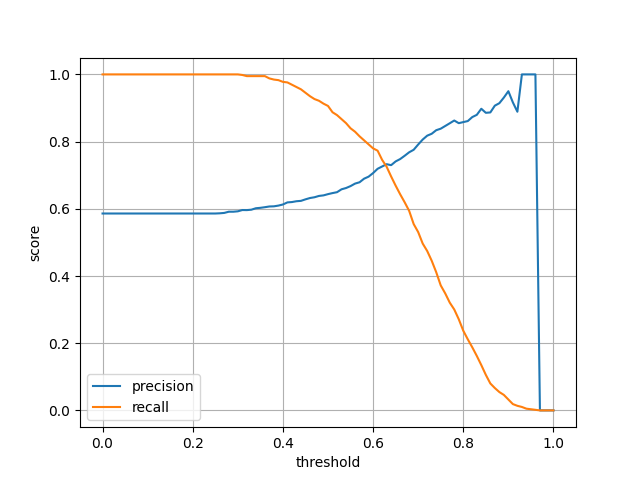

In [7]:
# Barremos umbrales, calculamos precision/recall y graficamos
thresholds = np.arange(0.0, 1.001, 0.01)
rows = []
for t in thresholds:
    pred = y_pred >= t
    tp = int((pred & (y_val == 1)).sum())
    fp = int((pred & (y_val == 0)).sum())
    fn = int(((~pred) & (y_val == 1)).sum())
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(float(t), 2), p, r))
pr = pd.DataFrame(rows, columns=["threshold", "precision", "recall"])
plt.figure()
plt.plot(pr.threshold, pr.precision, label="precision")
plt.plot(pr.threshold, pr.recall, label="recall")
plt.xlabel("threshold")
plt.ylabel("score")
plt.legend()
plt.grid(True)
plt.savefig("q3_precision_recall.png")
plt.close()
nz = pr[~((pr.precision == 0) & (pr.recall == 0))].copy()
nz["gap"] = (nz.precision - nz.recall).abs()
best_t = float(nz.sort_values("gap").iloc[0].threshold)
print("Intersection threshold:", best_t)
Image("q3_precision_recall.png")

## Q4: F1 score

Combinamos precision (P) y recall (R) con F1 = 2*P*R/(P+R) para cada umbral y graficamos la curva. El maximo indica el mejor equilibrio.

Best F1 threshold: 0.41


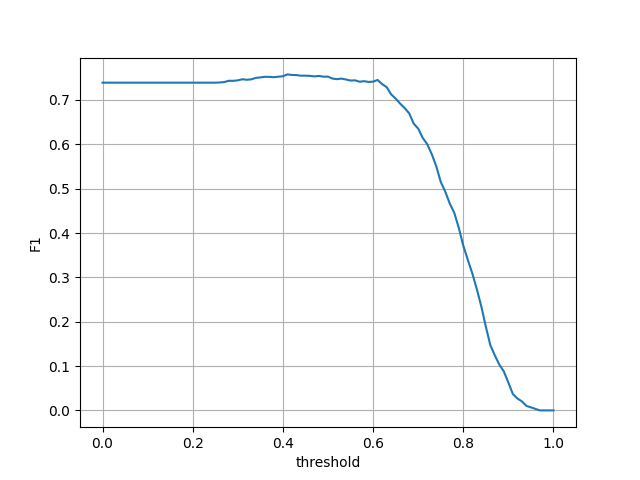

In [8]:
# F1 para cada umbral y su grafica
f1_rows = []
for t, p, r in rows:
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    f1_rows.append((t, f1))
f1df = pd.DataFrame(f1_rows, columns=["threshold", "f1"])
plt.figure()
plt.plot(f1df.threshold, f1df.f1)
plt.xlabel("threshold")
plt.ylabel("F1")
plt.grid(True)
plt.savefig("q4_f1.png")
plt.close()
best_f1_t = float(f1df.sort_values("f1", ascending=False).iloc[0].threshold)
print("Best F1 threshold:", best_f1_t)
Image("q4_f1.png")

## Q5: 5-Fold CV

Evaluamos el modelo con `KFold(n_splits=5, shuffle=True, random_state=1)` sobre `df_full_train` y medimos la desviacion estandar de los AUC entre folds.

In [9]:
# 5-fold CV sobre df_full_train con los mismos parametros del modelo
dv5 = DictVectorizer()
X_full = dv5.fit_transform(df_full_train[features].to_dict(orient="records")).toarray()
y_full = df_full_train["converted"].values
kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for tr, va in kf.split(X_full):
    m = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    m.fit(X_full[tr], y_full[tr])
    scores.append(roc_auc_score(y_full[va], m.predict_proba(X_full[va])[:, 1]))
print([round(float(s), 4) for s in scores])
print("std:", round(float(np.std(scores)), 4))

[0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
std: 0.0069


## Q6: Hyperparameter Tuning

Repetimos el 5-fold CV para C en [0.000001, 0.001, 1] y comparamos media y std del AUC (redondeadas a 3 decimales). Desempates: menor std y luego menor C.

In [10]:
# Barrido de C con el mismo KFold; desempatamos por menor std y menor C
results = []
for Cval in [0.000001, 0.001, 1]:
    ss = []
    for tr, va in kf.split(X_full):
        m = LogisticRegression(solver="liblinear", C=Cval, max_iter=1000)
        m.fit(X_full[tr], y_full[tr])
        ss.append(roc_auc_score(y_full[va], m.predict_proba(X_full[va])[:, 1]))
    results.append((Cval, round(float(np.mean(ss)), 3), round(float(np.std(ss)), 3)))
    print(Cval, results[-1][1], results[-1][2])
best_C = min(results, key=lambda r: (-r[1], r[2], r[0]))
print("Best C:", best_C[0])

1e-06 0.617 0.019


0.001 0.749 0.01
1 0.732 0.007
Best C: 0.001


## Answers Summary

Respuestas para el formulario (calculadas por este notebook):

| Question | Answer |
|---|---|
| Q1 - best ROC AUC feature | `lead_score` (0.7882) |
| Q2 - validation AUC | **0.732** |
| Q3 - precision/recall intersection | **0.63** |
| Q4 - max F1 threshold | **0.41** |
| Q5 - CV std | **0.007** |
| Q6 - best C | **0.001** (mean 0.749) |

In [11]:
# Autocomprobacion: todo debe coincidir con las respuestas esperadas
assert (len(df_train), len(df_val), len(df_test)) == (3000, 1000, 1000)
assert best_q1 == "lead_score" and q1["lead_score"] == 0.7882
assert auc_val == 0.732
assert best_t == 0.63
assert best_f1_t == 0.41
assert round(float(np.std(scores)), 3) == 0.007
assert best_C[0] == 0.001
print("ALL CHECKS PASSED")

ALL CHECKS PASSED


## Notes

Todo usa `random_state=1`, asi que los resultados son identicos en cada ejecucion. Para reproducir: abre el notebook en VS Code/Jupyter con `homework4/` como carpeta de trabajo y haz **Restart & Run All**.